In [1]:
import os
import glob
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

BASE_PATH = "/kaggle/input/original-aitex-dataset/aitex_dataset"
DEFECT_DIR = os.path.join(BASE_PATH, "Defect_images")
NODEFECT_DIR = os.path.join(BASE_PATH, "NODefect_images")

def parse_filename(filepath, label):
    filename = os.path.basename(filepath)
    
    if 'mask' in filename:
        return None
        
    parts = filename.replace('.png', '').split('_')
    
    # [ImageNumber, DefectCode, FabricCode]
    # 0001_002_23.png -> ['0001', '002', '23']
    if len(parts) == 3:
        return {
            "filepath": filepath,
            "filename": filename,
            "image_id": parts[0],
            "defect_code": parts[1], # '000' for normal, others for defects
            "fabric_code": parts[2],
            "label": label # 'Defect' or 'No Defect'
        }
    else:
        return None

data = []

defect_files = glob.glob(os.path.join(DEFECT_DIR, "*.png"))
for f in defect_files:
    meta = parse_filename(f, "Defect")
    if meta: data.append(meta)

nodefect_files = glob.glob(os.path.join(NODEFECT_DIR, "**", "*.png"), recursive=True)
for f in nodefect_files:
    meta = parse_filename(f, "No Defect")
    if meta: data.append(meta)

df = pd.DataFrame(data)

print(f"Total Images Index: {len(df)}")
print("Sample rows:")
display(df.head())

Total Images Index: 247
Sample rows:


,filepath,filename,image_id,defect_code,fabric_code,label
0,/kaggle/input/original-aitex-dataset/aitex_dat...,0092_030_01.png,0092,030,01,Defect
1,/kaggle/input/original-aitex-dataset/aitex_dat...,0107_025_03.png,0107,025,03,Defect
2,/kaggle/input/original-aitex-dataset/aitex_dat...,0101_022_03.png,0101,022,03,Defect
3,/kaggle/input/original-aitex-dataset/aitex_dat...,0043_019_04.png,0043,019,04,Defect
4,/kaggle/input/original-aitex-dataset/aitex_dat...,0028_019_02.png,0028,019,02,Defect


Unique Defect Codes found: 13
Codes: ['00', '002', '006', '010', '016', '019', '022', '023', '025', '027', '029', '030', '036']


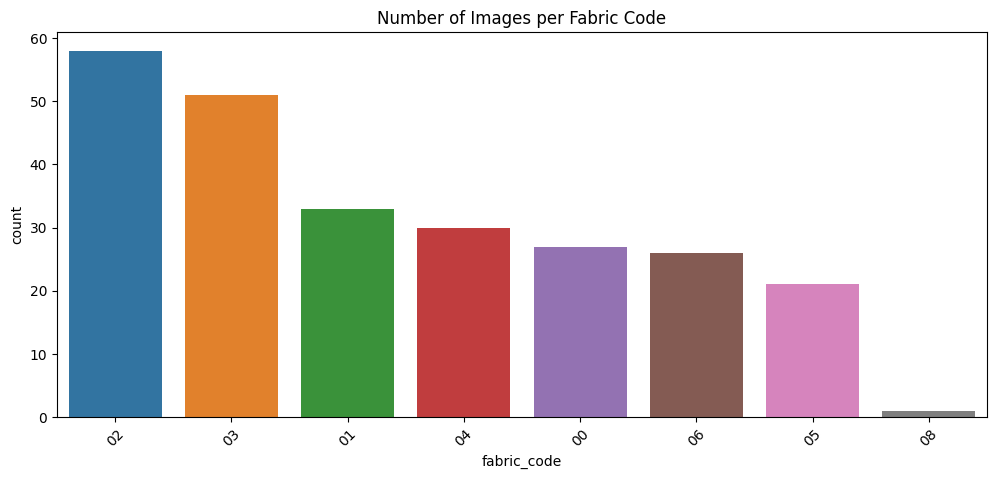


Defect vs No-Defect breakdown per fabric:


label,Defect,No Defect
fabric_code,,
00,7,20
01,12,21
02,38,20
03,31,20
04,10,20
05,1,20
06,6,20
08,1,0


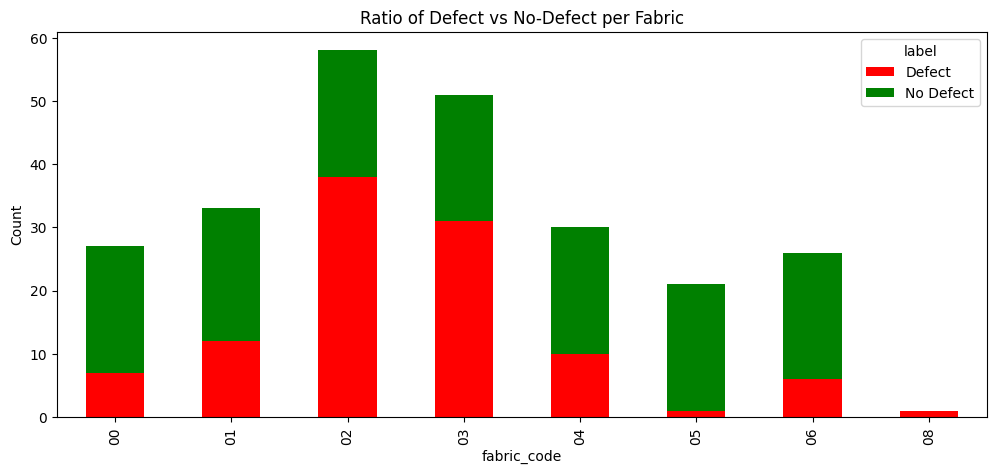

In [2]:
# HOW MANY DEFECT TYPES?
# Exclude '000' : "No Defect"
defect_types = df[df['defect_code'] != '000']['defect_code'].unique()
print(f"Unique Defect Codes found: {len(defect_types)}")
print(f"Codes: {sorted(defect_types)}")

# FABRIC DISTRIBUTION
# Which fabrics are most common?
plt.figure(figsize=(12, 5))
sns.countplot(data=df, x='fabric_code', order=df['fabric_code'].value_counts().index)
plt.title("Number of Images per Fabric Code")
plt.xticks(rotation=45)
plt.show()

# DEFECTS PER FABRIC (The Heatmap)
crosstab = pd.crosstab(df['fabric_code'], df['label'])
print("\nDefect vs No-Defect breakdown per fabric:")
display(crosstab)

# Visualize it
crosstab.plot(kind='bar', stacked=True, figsize=(12, 5), color=['red', 'green'])
plt.title("Ratio of Defect vs No-Defect per Fabric")
plt.ylabel("Count")
plt.show()

In [4]:
# Show defect type distribution
defect_info = df[df['label'] == 'Defect'].groupby('defect_code').size().sort_values(ascending=False)
print("Defect Distribution:")
print(defect_info)

# Check which defects are most common on which fabrics
print("\nDefects by Fabric:")
print(pd.crosstab(df[df['label']=='Defect']['fabric_code'], 
                   df[df['label']=='Defect']['defect_code']))

Defect Distribution:
defect_code
019    39
030    14
010    10
002     9
022     9
006     8
025     6
023     5
016     3
027     1
029     1
036     1
dtype: int64

Defects by Fabric:
defect_code  002  006  010  016  019  022  023  025  027  029  030  036
fabric_code                                                            
00             3    0    0    0    0    4    0    0    0    0    0    0
01             5    0    0    0    1    0    2    0    0    0    3    1
02             1    7    0    0   23    0    3    0    0    0    4    0
03             0    0   10    3    5    3    0    5    0    0    5    0
04             0    1    0    0    6    0    0    0    0    1    2    0
05             0    0    0    0    0    0    0    0    1    0    0    0
06             0    0    0    0    4    2    0    0    0    0    0    0
08             0    0    0    0    0    0    0    1    0    0    0    0


Most common defect is: 019


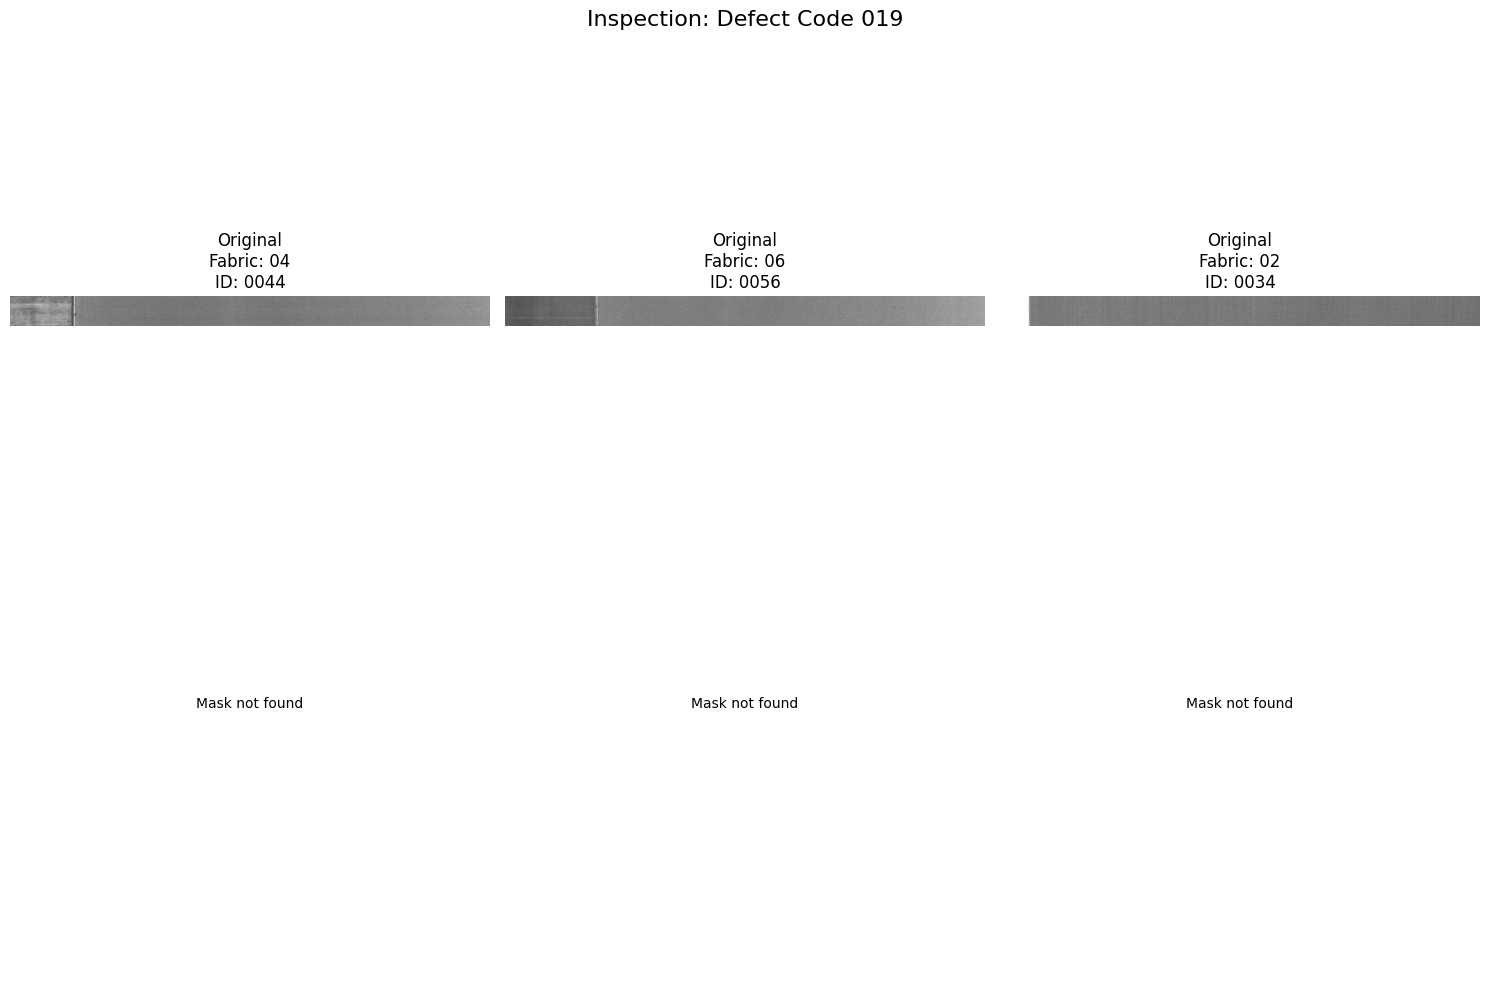

In [3]:
import cv2
import os

def inspect_defect_code_with_mask(target_code, n_samples=3):
    samples = df[df['defect_code'] == target_code].sample(n=min(n_samples, len(df)))
    
    if len(samples) == 0:
        print(f"No images found for defect code {target_code}")
        return
    
    plt.figure(figsize=(15, 10))
    plt.suptitle(f"Inspection: Defect Code {target_code}", fontsize=16)
    
    for i, (_, row) in enumerate(samples.iterrows()):
        img_path = row['filepath']
        
        # Load original image
        img = cv2.imread(img_path)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        
        # Construct mask path 
        mask_path = img_path.replace('.png', '_mask.png')
        
        # Display original image
        plt.subplot(2, n_samples, i+1)
        plt.imshow(img)
        plt.title(f"Original\nFabric: {row['fabric_code']}\nID: {row['image_id']}")
        plt.axis('off')
        
        # Display mask if it exists
        if os.path.exists(mask_path):
            mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
            plt.subplot(2, n_samples, n_samples + i+1)
            plt.imshow(mask, cmap='hot')  # Use 'hot' colormap to highlight defects
            plt.title(f"Defect Mask")
            plt.axis('off')
        else:
            plt.subplot(2, n_samples, n_samples + i+1)
            plt.text(0.5, 0.5, 'Mask not found', ha='center', va='center')
            plt.axis('off')
    
    plt.tight_layout()
    plt.show()

most_common_defect = df[df['label']=='Defect']['defect_code'].mode()[0]
print(f"Most common defect is: {most_common_defect}")
inspect_defect_code_with_mask(most_common_defect)